# NIM : 11322004
# Nama : Destina Manurung
# Prodi : D3 Teknologi Informasi 2022

In [2]:
# Mengimport dataset dan menampilkan 5 data teratas

import pandas as pd
df = pd.read_csv("clustering.csv")
df.head()

,User ID,Instagram visit score,Spending_rank(0 to 100)
0,0,63,24.050708
1,1,61,25.223290
2,2,104,18.528245
3,3,82,86.890232
4,4,14,31.492397


In [3]:
# Cek Missing Value

df.isnull().sum()

User ID                    0
Instagram visit score      0
Spending_rank(0 to 100)    0
dtype: int64

In [4]:
# Menampilkan ringkasan statistik dari data

df.describe()

,User ID,Instagram visit score,Spending_rank(0 to 100)
count,2600.000000,2600.000000,2600.000000
mean,1299.500000,63.323462,42.848408
std,750.699674,26.579760,28.758349
min,0.000000,5.000000,0.940709
25%,649.750000,38.000000,19.452098
50%,1299.500000,72.000000,28.013082
75%,1949.250000,86.000000,72.116945
max,2599.000000,118.000000,107.349821


In [10]:
# Memilih kolom mulai dari indeks 1 hingga akhir

dataset = df.iloc[:,1:] 
dataset.head()

,Instagram visit score,Spending_rank(0 to 100)
0,63,24.050708
1,61,25.223290
2,104,18.528245
3,82,86.890232
4,14,31.492397


In [12]:
# Membuat scatter plot menggunakan matplotlib

x = df.iloc[:,	1]	
y = df.iloc[:,	2]	

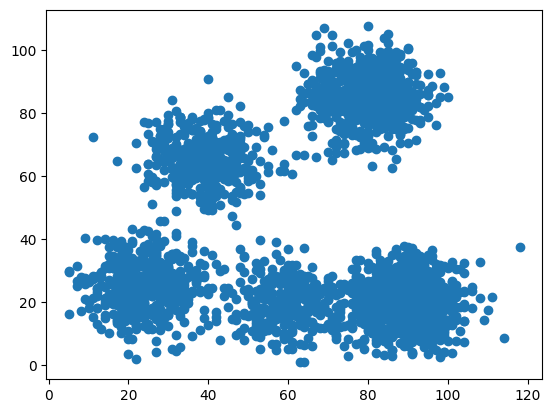

In [13]:
import matplotlib.pyplot as plt 
plt.scatter(x, y)
plt.show()

## Menggunakan Metode Elbow untuk menentukan jumlah klaster optimal dalam K-Means Clustering

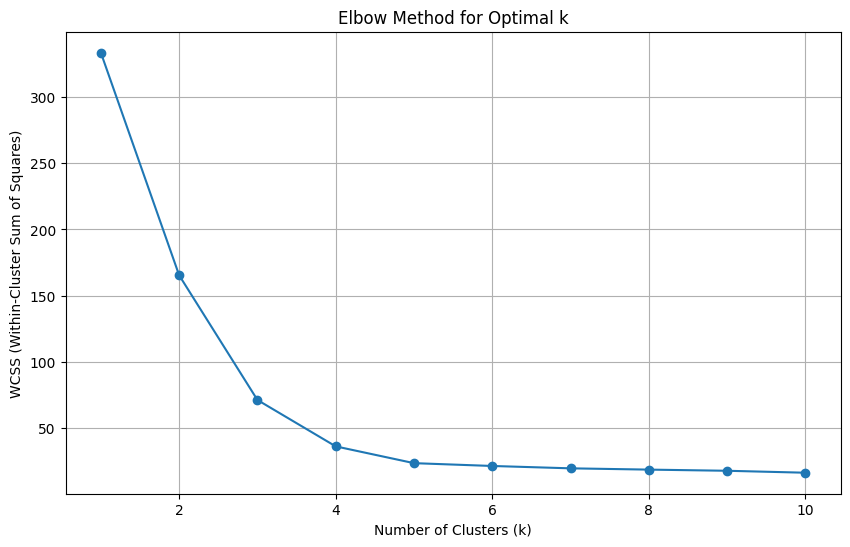

In [15]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

# Scaling data dengan MinMaxScaler
scaler = MinMaxScaler()

# Mengambil kolom X (index 1) dan Y (index 2) dari DataFrame
X = pd.DataFrame({'Instagram visit score': x, 'Spending_rank(0 to 100)': y}) 
X_scaled = scaler.fit_transform(X)
# Menentukan jumlah klaster optimal menggunakan Elbow Method
wcss = []
for i in range(1, 11): # Coba k dari 1 sampai 10 
    kmeans = KMeans(n_clusters=i, random_state=42) 
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Membuat plot Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-') 
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

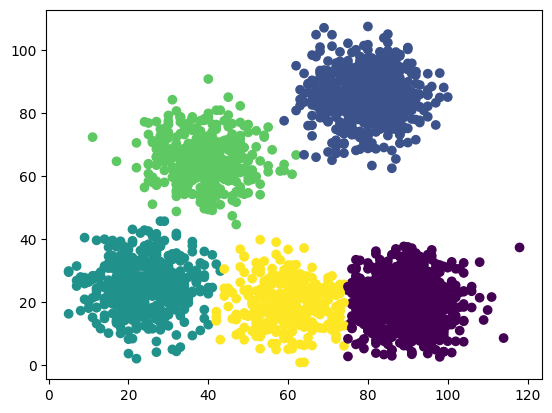

In [16]:
# dari elbow method, nilai k optimal untuk data ini adalah 5
kmeans = KMeans(n_clusters=5) 
kmeans.fit(X)

# Plot hasil klaster
plt.scatter(x, y, c=kmeans.labels_) 
plt.show()

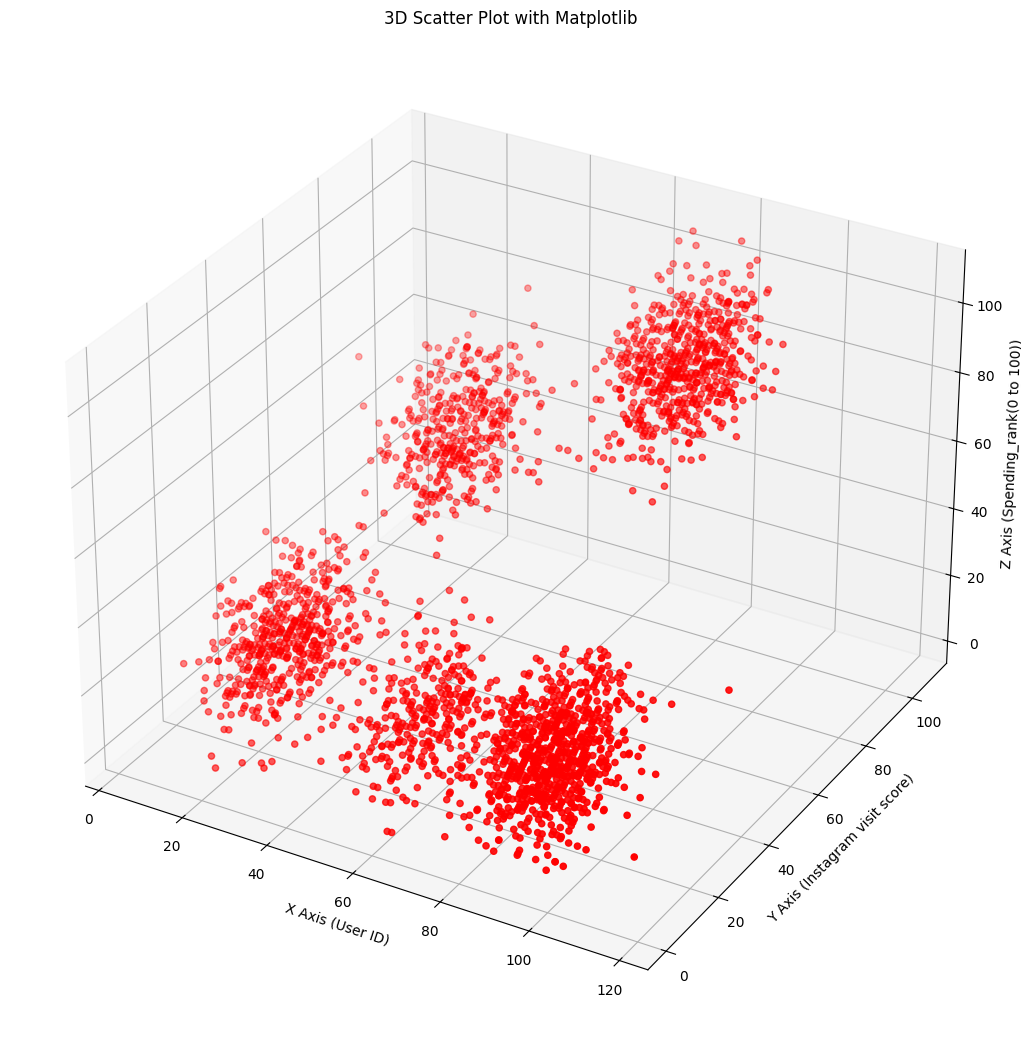

In [18]:
# Membuat scatter plot 3D menggunakan Matploblib untuk memvisualisasikan hubungan antara User ID, Instagram visit score, Spending_rank(0 to 100)

from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Data Age, Annual Income, dan Spending Score
x = df.iloc[:, 1]
y = df.iloc[:, 2]
z = df.iloc[:, 2]

# Membuat plot 3D
fig = plt.figure(figsize=(13, 13))
ax = fig.add_subplot(111, projection='3d')

# Plot data
ax.scatter(x, y, z, c='red', marker='o')

# Label sumbu
ax.set_xlabel('X Axis (User ID)')
ax.set_ylabel('Y Axis (Instagram visit score)')
ax.set_zlabel('Z Axis (Spending_rank(0 to 100))')

plt.title('3D Scatter Plot with Matplotlib') 
plt.show()